# Task 1


In [ ]:
!unzip /content/fire.zip

Archive:  /content/fire.zip
  inflating: fire_dataset/fire_images/fire.1.png  
  inflating: fire_dataset/fire_images/fire.10.png  
  inflating: fire_dataset/fire_images/fire.100.png  
  inflating: fire_dataset/fire_images/fire.101.png  
  inflating: fire_dataset/fire_images/fire.102.png  
  inflating: fire_dataset/fire_images/fire.103.png  
  inflating: fire_dataset/fire_images/fire.104.png  
  inflating: fire_dataset/fire_images/fire.105.png  
  inflating: fire_dataset/fire_images/fire.106.png  
  inflating: fire_dataset/fire_images/fire.107.png  
  inflating: fire_dataset/fire_images/fire.108.png  
  inflating: fire_dataset/fire_images/fire.109.png  
  inflating: fire_dataset/fire_images/fire.11.png  
  inflating: fire_dataset/fire_images/fire.110.png  
  inflating: fire_dataset/fire_images/fire.111.png  
  inflating: fire_dataset/fire_images/fire.112.png  
  inflating: fire_dataset/fire_images/fire.113.png  
  inflating: fire_dataset/fire_images/fire.114.png  
  inflating: fire_data

In [ ]:
import cv2
import os
import numpy as np

# Define the paths for the image directories
fire_images_dir = '/content/fire_dataset/fire_images'
non_fire_images_dir = '/content/fire_dataset/non_fire_images'

# Create empty lists to store preprocessed images and their labels
images = []
labels = []

image_size = (227, 227)
max_images_per_class = 300

# Loop through the 'fire_images' directory
fire_image_count = 0
for filename in os.listdir(fire_images_dir):
    if fire_image_count >= max_images_per_class:
        break
    if filename.endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(fire_images_dir, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.resize(img, image_size)
            images.append(img)
            labels.append(1)  # Label 1 for fire
            fire_image_count += 1

# Loop through the 'non_fire_images' directory
non_fire_image_count = 0
for filename in os.listdir(non_fire_images_dir):
    if non_fire_image_count >= max_images_per_class:
        break
    if filename.endswith(('.png', '.jpg', '.jpeg')):
        img_path = os.path.join(non_fire_images_dir, filename)
        img = cv2.imread(img_path)
        if img is not None:
            img = cv2.resize(img, image_size)
            images.append(img)
            labels.append(0)  # Label 0 for non-fire
            non_fire_image_count += 1

# Convert the lists to NumPy arrays
X = np.array(images).astype('float32')
y = np.array(labels)

# Normalize image data to [0, 1]
X /= 255.0

print(f"Total images loaded: {len(X)}")
print(f"Total labels loaded: {len(y)}")
print(f"Shape of images array: {X.shape}")
print(f"Shape of labels array: {y.shape}")
print(f"Number of fire images: {fire_image_count}")
print(f"Number of non-fire images: {non_fire_image_count}")

Total images loaded: 544
Total labels loaded: 544
Shape of images array: (544, 227, 227, 3)
Shape of labels array: (544,)
Number of fire images: 300
Number of non-fire images: 244


In [ ]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_test: {X_test.shape}")
print(f"Shape of y_train: {y_train.shape}")
print(f"Shape of y_test: {y_test.shape}")
print(f"Number of unique classes in y_train: {np.unique(y_train)}")
print(f"Number of unique classes in y_test: {np.unique(y_test)}")

Shape of X_train: (435, 227, 227, 3)
Shape of X_test: (109, 227, 227, 3)
Shape of y_train: (435,)
Shape of y_test: (109,)
Number of unique classes in y_train: [0 1]
Number of unique classes in y_test: [0 1]


# Task 2


In [ ]:
import torch
import torchvision.models as models

# Load the pre-trained AlexNet model with ImageNet weights
alexnet_model = models.alexnet(pretrained=True)

print("Pre-trained AlexNet model loaded successfully.")

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 151MB/s]


Pre-trained AlexNet model loaded successfully.


In [ ]:
import torch.nn as nn

# Freeze all parameters in the AlexNet model
for param in alexnet_model.parameters():
    param.requires_grad = False

# Modify the classifier to remove the last classification layer.
# The original classifier has 7 sub-modules, with the last one (index 6) being the 1000-class output layer.
# We want the 4096-dimensional features from the layer before the final output.
# The layer at index 4 is a Linear layer outputting 4096 features.
# We'll retain layers up to index 5 (which is the ReLU activation after the 4096-feature linear layer).
# This will effectively extract the 4096-dimensional features before the final classification decision.
alexnet_model.classifier = nn.Sequential(*list(alexnet_model.classifier.children())[:-1])

# Set the model to evaluation mode
alexnet_model.eval()

print("AlexNet model modified for feature extraction and layers frozen.")
print(alexnet_model)

AlexNet model modified for feature extraction and layers frozen.
AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6))
  (classifier): Sequential(
    (0): Dropout(p=0.5, inplace=False)


In [ ]:
import torchvision.transforms as transforms
import torch

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
alexnet_model.to(device)

# Define the preprocessing pipeline for AlexNet
# AlexNet expects 224x224 images, but we resized to 227x227, which is fine.
# Normalize with ImageNet mean and standard deviation.
transform = transforms.Compose([
    transforms.ToPILImage(), # Convert numpy array to PIL Image for transforms
    transforms.Resize((227, 227)), # Resize to AlexNet's input size (already done, but good practice)
    transforms.ToTensor(), # Convert PIL Image to PyTorch Tensor
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]) # ImageNet normalization
])

def extract_features(dataset, model, transform, device):
    features = []
    for img_array in dataset:
        # Convert normalized numpy array to original 0-255 range then to PIL Image
        # X was normalized to [0,1], so convert back to [0,255] uint8 for ToPILImage
        img_array_unnormalized = (img_array * 255).astype(np.uint8)
        img_tensor = transform(img_array_unnormalized).unsqueeze(0).to(device)
        with torch.no_grad():
            feature = model(img_tensor)
        features.append(feature.cpu().numpy().flatten()) # Flatten to get 1D feature vector
    return np.array(features)

# Extract features for training data
X_train_features = extract_features(X_train, alexnet_model, transform, device)

# Extract features for testing data
X_test_features = extract_features(X_test, alexnet_model, transform, device)

print(f"Shape of X_train_features: {X_train_features.shape}")
print(f"Shape of X_test_features: {X_test_features.shape}")

Shape of X_train_features: (435, 4096)
Shape of X_test_features: (109, 4096)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Initialize the Logistic Regression classifier
# Set max_iter to a higher value to ensure convergence
classifier = LogisticRegression(max_iter=1000, random_state=42)

# Train the classifier using the extracted features and labels
classifier.fit(X_train_features, y_train)

print("Logistic Regression classifier trained successfully.")

Logistic Regression classifier trained successfully.


Accuracy: 0.9633
Precision: 0.9516
Recall: 0.9833
F1-Score: 0.9672


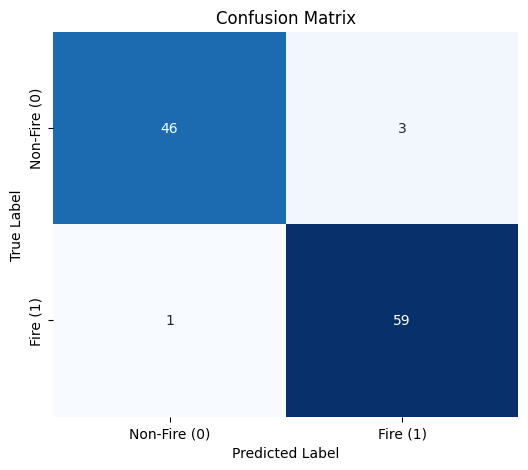


Classification Report:
              precision    recall  f1-score   support

           0       0.98      0.94      0.96        49
           1       0.95      0.98      0.97        60

    accuracy                           0.96       109
   macro avg       0.97      0.96      0.96       109
weighted avg       0.96      0.96      0.96       109



In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Make predictions on the test set
y_pred = classifier.predict(X_test_features)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")

# Generate Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=['Non-Fire (0)', 'Fire (1)'], yticklabels=['Non-Fire (0)', 'Fire (1)'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Generate Classification Report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

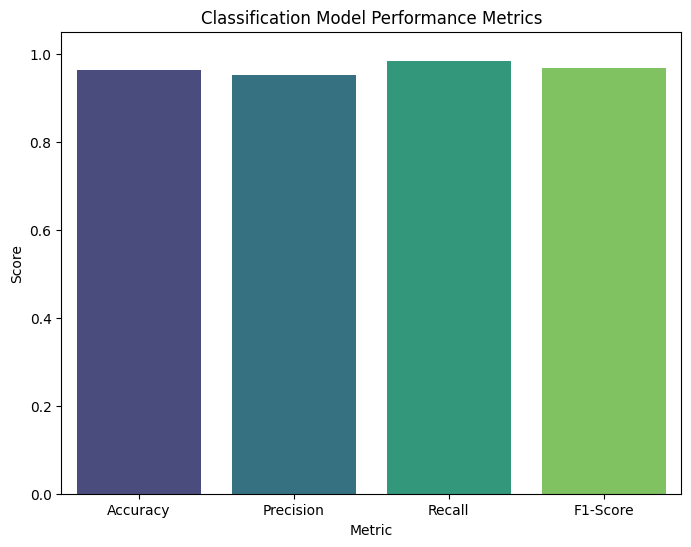

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for visualization
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
scores = [accuracy, precision, recall, f1]

# Create a bar chart for the metrics
plt.figure(figsize=(8, 6))
sns.barplot(x=metrics, y=scores, hue=metrics, palette='viridis', legend=False)
plt.ylim(0, 1.05) # Set y-axis limit from 0 to 1 for scores
plt.xlabel('Metric')
plt.ylabel('Score')
plt.title('Classification Model Performance Metrics')
plt.show()


# Task 3




In [ ]:
import torch
import torchvision.models as models

# Load the pre-trained AlexNet model with ImageNet weights
alexnet_model = models.alexnet(weights=models.AlexNet_Weights.DEFAULT)

print("Pre-trained AlexNet model loaded successfully for fine-tuning.")

Pre-trained AlexNet model loaded successfully for fine-tuning.


In [ ]:
import torch.nn as nn

# Set the model to training mode
alexnet_model.train()

# Freeze parameters in the 'features' part of the model
for param in alexnet_model.features.parameters():
    param.requires_grad = False

# Freeze parameters in the 'avgpool' part of the model
for param in alexnet_model.avgpool.parameters():
    param.requires_grad = False

# Get the number of in_features of the original last classification layer
# The original classifier is Sequential(
#   (0): Dropout(p=0.5, inplace=False)
#   (1): Linear(in_features=9216, out_features=4096, bias=True)
#   (2): ReLU(inplace=True)
#   (3): Dropout(p=0.5, inplace=False)
#   (4): Linear(in_features=4096, out_features=4096, bias=True)
#   (5): ReLU(inplace=True)
#   (6): Linear(in_features=4096, out_features=1000, bias=True)
# )
# We need the in_features of the layer at index 6 (the original final linear layer)
in_features = alexnet_model.classifier[6].in_features

# Replace the final classification layer with a new one for 2 classes
alexnet_model.classifier[6] = nn.Linear(in_features, 2)

print("AlexNet model modified for fine-tuning with 2 output classes.")
print("Frozen 'features' and 'avgpool' layers. New classifier layer trainable.")
print(alexnet_model)

# Verify which parameters are trainable
print("\nTrainable parameters:")
for name, param in alexnet_model.named_parameters():
    if param.requires_grad:
        print(name)

AlexNet model modified for fine-tuning with 2 output classes.
Frozen 'features' and 'avgpool' layers. New classifier layer trainable.
AlexNet(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(11, 11), stride=(4, 4), padding=(2, 2))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 192, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(192, 384, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(384, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=3, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(6, 6)

In [ ]:
from torch.utils.data import Dataset, DataLoader
import torch.optim as optim
import torch.nn as nn

# Define the device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
alexnet_model.to(device)

# --- 2. Define a custom PyTorch Dataset class ---
class CustomImageDataset(Dataset):
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        image = self.images[idx]
        label = self.labels[idx]

        # Convert numpy array to original 0-255 range then to PIL Image
        # X_train and X_test were normalized to [0,1], so convert back to [0,255] uint8 for ToPILImage
        image = (image * 255).astype(np.uint8)

        if self.transform:
            image = self.transform(image)

        # Ensure label is a long tensor for CrossEntropyLoss
        label = torch.tensor(label, dtype=torch.long)

        return image, label

# --- 3. Create instances of this custom Dataset ---
# The 'transform' object is already defined in a previous step, which includes:
# transforms.ToPILImage(), transforms.Resize((227, 227)), transforms.ToTensor(), transforms.Normalize(...)

train_dataset = CustomImageDataset(X_train, y_train, transform=transform)
test_dataset = CustomImageDataset(X_test, y_test, transform=transform)

# --- 4. Create DataLoader instances ---
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Training DataLoader created with {len(train_loader.dataset)} samples and batch size {train_loader.batch_size}.")
print(f"Testing DataLoader created with {len(test_loader.dataset)} samples and batch size {test_loader.batch_size}.")

# --- 5. Define the loss function ---
criterion = nn.CrossEntropyLoss()
print("Loss function (CrossEntropyLoss) defined.")

# --- 6. Define the optimizer ---
# Only parameters with requires_grad=True will be optimized
optimizer = optim.Adam(filter(lambda p: p.requires_grad, alexnet_model.parameters()), lr=0.001)
print("Optimizer (Adam) defined, optimizing only trainable layers.")


Training DataLoader created with 435 samples and batch size 32.
Testing DataLoader created with 109 samples and batch size 32.
Loss function (CrossEntropyLoss) defined.
Optimizer (Adam) defined, optimizing only trainable layers.


In [ ]:
num_epochs = 10

# Lists to store metrics
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []

print("Starting model training...")

for epoch in range(num_epochs):
    # Training Phase
    alexnet_model.train()  # Set model to training mode
    running_train_loss = 0.0
    correct_train = 0
    total_train = 0

    for inputs, labels in train_loader:
        inputs, labels = inputs.to(device), labels.to(device)

        optimizer.zero_grad()  # Zero the parameter gradients

        outputs = alexnet_model(inputs) # Forward pass
        loss = criterion(outputs, labels) # Calculate loss
        loss.backward()  # Backward pass
        optimizer.step()  # Optimize

        running_train_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total_train += labels.size(0)
        correct_train += (predicted == labels).sum().item()

    epoch_train_loss = running_train_loss / total_train
    epoch_train_accuracy = 100 * correct_train / total_train

    train_losses.append(epoch_train_loss)
    train_accuracies.append(epoch_train_accuracy)

    # Validation Phase
    alexnet_model.eval()  # Set model to evaluation mode
    running_val_loss = 0.0
    correct_val = 0
    total_val = 0

    with torch.no_grad():  # Disable gradient calculation for validation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            outputs = alexnet_model(inputs)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_val += labels.size(0)
            correct_val += (predicted == labels).sum().item()

    epoch_val_loss = running_val_loss / total_val
    epoch_val_accuracy = 100 * correct_val / total_val

    val_losses.append(epoch_val_loss)
    val_accuracies.append(epoch_val_accuracy)

    print(f"Epoch {epoch+1}/{num_epochs}: "
          f"Train Loss: {epoch_train_loss:.4f}, Train Acc: {epoch_train_accuracy:.2f}% | "
          f"Val Loss: {epoch_val_loss:.4f}, Val Acc: {epoch_val_accuracy:.2f}%")

print("Training complete.")

Starting model training...
Epoch 1/10: Train Loss: 0.8266, Train Acc: 89.89% | Val Loss: 0.8260, Val Acc: 92.66%
Epoch 2/10: Train Loss: 0.3108, Train Acc: 95.86% | Val Loss: 0.5612, Val Acc: 95.41%
Epoch 3/10: Train Loss: 0.2594, Train Acc: 95.40% | Val Loss: 0.3792, Val Acc: 95.41%
Epoch 4/10: Train Loss: 0.0973, Train Acc: 97.24% | Val Loss: 0.6177, Val Acc: 94.50%
Epoch 5/10: Train Loss: 0.0878, Train Acc: 97.93% | Val Loss: 1.1590, Val Acc: 94.50%
Epoch 6/10: Train Loss: 0.0012, Train Acc: 100.00% | Val Loss: 0.6206, Val Acc: 96.33%
Epoch 7/10: Train Loss: 0.0486, Train Acc: 99.08% | Val Loss: 1.0231, Val Acc: 97.25%
Epoch 8/10: Train Loss: 0.1394, Train Acc: 98.62% | Val Loss: 3.9569, Val Acc: 88.99%
Epoch 9/10: Train Loss: 0.2119, Train Acc: 98.16% | Val Loss: 1.1229, Val Acc: 94.50%
Epoch 10/10: Train Loss: 0.1830, Train Acc: 97.24% | Val Loss: 0.8089, Val Acc: 95.41%
Training complete.


#Task 4

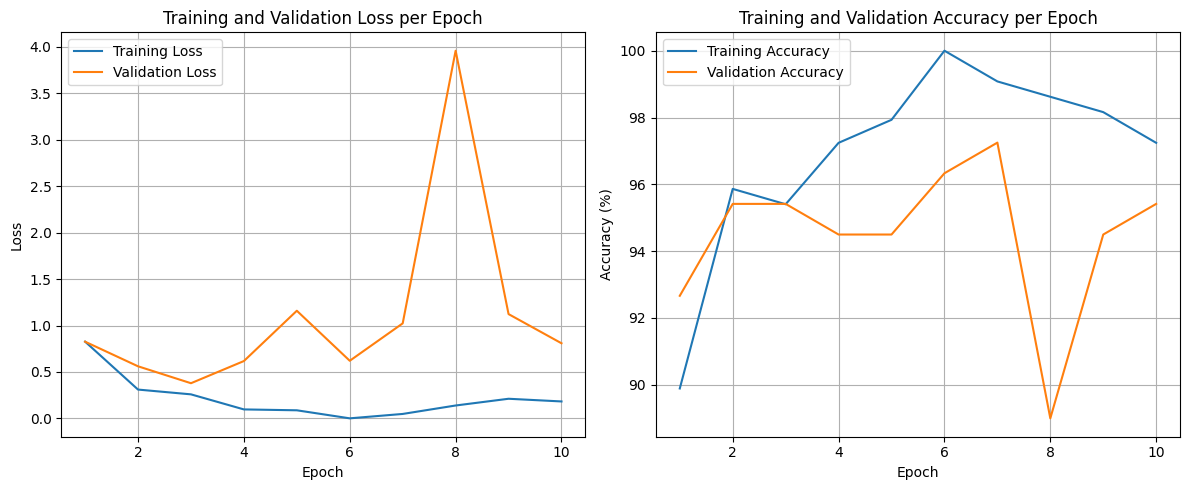

In [ ]:
import matplotlib.pyplot as plt

# Plotting training and validation loss
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(range(1, num_epochs + 1), train_losses, label='Training Loss')
plt.plot(range(1, num_epochs + 1), val_losses, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss per Epoch')
plt.legend()
plt.grid(True)

# Plotting training and validation accuracy
plt.subplot(1, 2, 2)
plt.plot(range(1, num_epochs + 1), train_accuracies, label='Training Accuracy')
plt.plot(range(1, num_epochs + 1), val_accuracies, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.title('Training and Validation Accuracy per Epoch')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()